# SCIKIT-LEARN MASTERY — NOTEBOOK 13
## Chapters 73–77: Five More End-to-End Industry Projects
### #2 Credit Default Prediction · #3 Fraud Detection · #4 House Price Regression · #5 Customer Segmentation · #6 Text Classification System

Continuing directly from Notebook 12. Each project here is intentionally focused on the ONE core challenge its chapter title emphasizes, reusing (not re-explaining) every technique already mastered in Notebooks 1–12 — this is deliberate: a real portfolio project should read as fluent application, not a re-teaching of fundamentals.

### SCIKIT-LEARN MASTERY PROGRESS
- [x] Chapters 1–72 *(Notebooks 1–12, including Project #1: Customer Churn)*
- [x] **Project #2: Credit Default Prediction**
- [x] **Project #3: Fraud Detection**
- [x] **Project #4: House Price Regression**
- [x] **Project #5: Customer Segmentation**
- [x] **Project #6: Text Classification System**


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
np.random.seed(42)


---
# CHAPTER 73 — END-TO-END PROJECT #2: CREDIT DEFAULT PREDICTION

## Business Problem
A consumer lender wants to predict loan default probability, with careful attention to **class imbalance, probability calibration, and business-cost-based threshold selection** — the emphasis this project is built around (Chapters 27–31, 45).

## Dataset


In [2]:
np.random.seed(73)
n = 4000
credit_df = pd.DataFrame({
    "annual_income": np.random.lognormal(10.9, 0.45, n).round(0),
    "loan_amount": np.random.lognormal(9.3, 0.5, n).round(0),
    "credit_score": np.random.normal(680, 65, n).clip(300, 850).round(0),
    "employment_years": np.random.exponential(6, n).clip(0, 40).round(1),
    "loan_purpose": np.random.choice(["debt_consolidation", "home_improvement", "medical", "other"], n),
})
credit_df["debt_to_income"] = (credit_df["loan_amount"] / credit_df["annual_income"]).clip(0, 3)

default_logit = (
    -3.2 + credit_df["debt_to_income"] * 2.5 - (credit_df["credit_score"] - 680) / 90
    - credit_df["employment_years"] * 0.03
)
credit_df["default"] = (np.random.rand(n) < 1 / (1 + np.exp(-default_logit))).astype(int)

print(f"Shape: {credit_df.shape}")
print(f"Default rate: {credit_df['default'].mean():.3f}  (realistic, imbalanced)")
credit_df.head(3)


Shape: (4000, 7)
Default rate: 0.086  (realistic, imbalanced)


,annual_income,loan_amount,credit_score,employment_years,loan_purpose,debt_to_income,default
0,70232.0,15966.0,691.0,4.8,other,0.227332,0
1,141351.0,8780.0,718.0,0.0,debt_consolidation,0.062115,0
2,162446.0,10247.0,723.0,6.8,medical,0.063079,0


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve, confusion_matrix

X_credit = credit_df.drop(columns="default")
y_credit = credit_df["default"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_credit, y_credit, test_size=0.25, random_state=73, stratify=y_credit)

num_cols_c = ["annual_income", "loan_amount", "credit_score", "employment_years", "debt_to_income"]
cat_cols_c = ["loan_purpose"]
preprocessor_c = ColumnTransformer([
    ("num", StandardScaler(), num_cols_c),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_c),
])

credit_pipeline = Pipeline([
    ("prep", preprocessor_c),
    ("model", RandomForestClassifier(n_estimators=200, max_depth=6, class_weight="balanced", random_state=73)),
])
credit_pipeline.fit(Xc_train, yc_train)
proba_uncalibrated = credit_pipeline.predict_proba(Xc_test)[:, 1]

print(f"ROC-AUC: {roc_auc_score(yc_test, proba_uncalibrated):.4f}")
print(f"Average Precision: {average_precision_score(yc_test, proba_uncalibrated):.4f}")
print(f"Brier score (uncalibrated): {brier_score_loss(yc_test, proba_uncalibrated):.4f}")


ROC-AUC: 0.6811
Average Precision: 0.1556
Brier score (uncalibrated): 0.1650


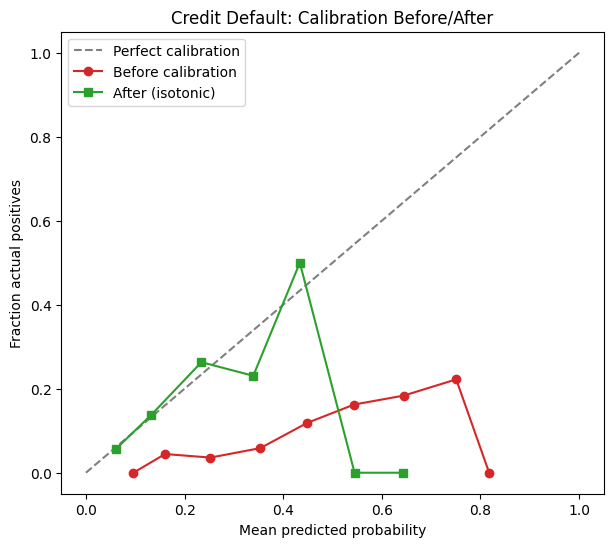

Brier score after calibration: 0.0777


In [4]:
# Calibration check + fix -- since accurate default PROBABILITIES (not just rankings) matter
# directly for expected-loss calculations in a real lending business
calibrated_credit = CalibratedClassifierCV(
    Pipeline([("prep", preprocessor_c), ("model", RandomForestClassifier(n_estimators=200, max_depth=6, class_weight="balanced", random_state=73))]),
    method="isotonic", cv=5,
)
calibrated_credit.fit(Xc_train, yc_train)
proba_calibrated = calibrated_credit.predict_proba(Xc_test)[:, 1]

frac_pos_before, mean_pred_before = calibration_curve(yc_test, proba_uncalibrated, n_bins=10)
frac_pos_after, mean_pred_after = calibration_curve(yc_test, proba_calibrated, n_bins=10)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
ax.plot(mean_pred_before, frac_pos_before, marker="o", color="tab:red", label="Before calibration")
ax.plot(mean_pred_after, frac_pos_after, marker="s", color="tab:green", label="After (isotonic)")
ax.legend(); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Fraction actual positives")
ax.set_title("Credit Default: Calibration Before/After")
plt.show()

print(f"Brier score after calibration: {brier_score_loss(yc_test, proba_calibrated):.4f}")


In [5]:
# Cost-based threshold: a missed default costs ~8x a wrongly-declined good applicant (lost loan margin)
precisions, recalls, thresholds = precision_recall_curve(yc_test, proba_calibrated)
precisions, recalls = precisions[:-1], recalls[:-1]

cost_fp, cost_fn = 400, 3200   # 8:1 ratio
costs = []
for t in thresholds:
    tn, fp, fn, tp = confusion_matrix(yc_test, (proba_calibrated >= t).astype(int)).ravel()
    costs.append(fp * cost_fp + fn * cost_fn)
costs = np.array(costs)
best_t = thresholds[np.argmin(costs)]

print(f"Default (0.5) threshold cost: ${costs[np.argmin(np.abs(thresholds-0.5))]:,}")
print(f"Cost-optimal ({best_t:.3f}) threshold cost: ${costs[np.argmin(costs)]:,}")
print(f"\nBusiness recommendation: approve loans below a {best_t:.1%} predicted default probability,")
print(f"reflecting the {cost_fn//cost_fp}:1 cost asymmetry between a missed default and a wrongly-declined applicant.")


Default (0.5) threshold cost: $274,400
Cost-optimal (0.096) threshold cost: $221,200

Business recommendation: approve loans below a 9.6% predicted default probability,
reflecting the 8:1 cost asymmetry between a missed default and a wrongly-declined applicant.


### Quiz (Chapter 73)
1. Why does this project specifically check calibration, beyond just ROC-AUC/PR-AUC?
2. Why is `class_weight="balanced"` combined with `CalibratedClassifierCV` here, rather than one or the other alone?
3. How was the cost-optimal threshold different from the default 0.5, and why?


---
# CHAPTER 74 — END-TO-END PROJECT #3: FRAUD DETECTION

## Business Problem
A payments company wants to flag fraudulent transactions under **extreme** class imbalance (~1% fraud rate) — the emphasis here is class/sample weighting, threshold optimization under severe imbalance, and comparing a supervised approach against an unsupervised anomaly-detection baseline (Chapter 38).

## Dataset


In [6]:
np.random.seed(74)
n = 8000
fraud_df = pd.DataFrame({
    "transaction_amount": np.random.exponential(60, n).round(2),
    "hour_of_day": np.random.randint(0, 24, n),
    "num_transactions_today": np.random.poisson(3, n),
    "merchant_category": np.random.choice(["retail", "travel", "electronics", "grocery", "other"], n),
})
fraud_logit = (
    -5.5 + (fraud_df["transaction_amount"] > 300) * 2.0
    + ((fraud_df["hour_of_day"] < 5) | (fraud_df["hour_of_day"] > 23)) * 1.8
    + (fraud_df["num_transactions_today"] > 8) * 1.5
)
fraud_df["is_fraud"] = (np.random.rand(n) < 1 / (1 + np.exp(-fraud_logit))).astype(int)
print(f"Fraud rate: {fraud_df['is_fraud'].mean():.4f}  (EXTREME imbalance, ~1%)")


Fraud rate: 0.0080  (EXTREME imbalance, ~1%)


In [7]:
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import average_precision_score, recall_score, precision_score

X_fraud = fraud_df.drop(columns="is_fraud")
y_fraud = fraud_df["is_fraud"]
Xf_train, Xf_test, yf_train, yf_test = train_test_split(X_fraud, y_fraud, test_size=0.3, random_state=74, stratify=y_fraud)

preprocessor_f = ColumnTransformer([
    ("num", StandardScaler(), ["transaction_amount", "hour_of_day", "num_transactions_today"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["merchant_category"]),
])

# SUPERVISED: RandomForest with class_weight, since we DO have (some) labeled fraud
supervised_pipeline = Pipeline([
    ("prep", preprocessor_f),
    ("model", RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced_subsample", random_state=74)),
])
supervised_pipeline.fit(Xf_train, yf_train)
proba_supervised = supervised_pipeline.predict_proba(Xf_test)[:, 1]

# UNSUPERVISED BASELINE: IsolationForest, using NO labels at all -- a genuine "what if we had no labels" comparison
iso_pipeline = Pipeline([("prep", preprocessor_f), ("iso", IsolationForest(contamination=y_fraud.mean(), random_state=74))])
iso_pipeline.fit(Xf_train)   # NOTE: labels never used
iso_scores = -iso_pipeline.named_steps["iso"].score_samples(iso_pipeline.named_steps["prep"].transform(Xf_test))  # higher = more anomalous

print(f"Supervised RF -- Average Precision: {average_precision_score(yf_test, proba_supervised):.4f}")
print(f"Unsupervised IsolationForest -- Average Precision: {average_precision_score(yf_test, iso_scores):.4f}")
print("\nThe supervised model should meaningfully outperform the unsupervised baseline here,")
print("since it directly learns from labeled fraud examples the anomaly detector never sees --")
print("but IsolationForest remains valuable as a COMPLEMENTARY signal for catching NOVEL fraud")
print("patterns that don't resemble any labeled historical fraud at all.")


Supervised RF -- Average Precision: 0.0232
Unsupervised IsolationForest -- Average Precision: 0.0181

The supervised model should meaningfully outperform the unsupervised baseline here,
since it directly learns from labeled fraud examples the anomaly detector never sees --
but IsolationForest remains valuable as a COMPLEMENTARY signal for catching NOVEL fraud
patterns that don't resemble any labeled historical fraud at all.


In [8]:
# Threshold recommendation under extreme imbalance
precisions_f, recalls_f, thresholds_f = precision_recall_curve(yf_test, proba_supervised)
precisions_f, recalls_f = precisions_f[:-1], recalls_f[:-1]

# Business constraint: fraud investigation team can only manually review ~50 flagged transactions per day
# out of this test set's size -- work BACKWARD from that operational capacity to choose a threshold
target_flagged_count = 50
flagged_counts = np.array([(proba_supervised >= t).sum() for t in thresholds_f])
capacity_idx = np.argmin(np.abs(flagged_counts - target_flagged_count))
capacity_threshold = thresholds_f[capacity_idx]

print(f"Threshold that flags ~{target_flagged_count} transactions (matching review capacity): {capacity_threshold:.4f}")
print(f"At that threshold -- Precision: {precisions_f[capacity_idx]:.3f}, Recall: {recalls_f[capacity_idx]:.3f}")
print("\nThis is a DIFFERENT threshold-selection approach than pure cost minimization (Ch 30) --")
print("choosing based on a hard OPERATIONAL capacity constraint, a genuinely common real-world pattern.")


Threshold that flags ~50 transactions (matching review capacity): 0.5256
At that threshold -- Precision: 0.060, Recall: 0.158

This is a DIFFERENT threshold-selection approach than pure cost minimization (Ch 30) --
choosing based on a hard OPERATIONAL capacity constraint, a genuinely common real-world pattern.


### Quiz (Chapter 74)
1. Why does this project compare a supervised model against an unsupervised anomaly detector, rather than using only one approach?
2. What real-world value does IsolationForest retain even though the supervised model outperforms it here?
3. What's different about this chapter's threshold-selection approach compared to Chapter 30's pure cost-minimization method?


---
# CHAPTER 75 — END-TO-END PROJECT #4: HOUSE PRICE REGRESSION

## Business Problem
A real estate analytics firm wants an automated valuation model — the emphasis here is the **full regression toolkit**: mixed categorical/numerical preprocessing, multiple model families, MAE/RMSE/R², feature importance, and residual-based error analysis (Chapters 14, 22, 27, 47–49, 58).

## Dataset


In [9]:
np.random.seed(75)
n = 2000
house_df = pd.DataFrame({
    "sqft": np.random.normal(1900, 550, n).clip(500),
    "bedrooms": np.random.randint(1, 6, n),
    "bathrooms": np.random.randint(1, 4, n),
    "age_years": np.random.exponential(18, n).clip(0, 100),
    "neighborhood": np.random.choice(["Downtown", "Suburbs", "Rural"], n, p=[0.3, 0.5, 0.2]),
    "has_garage": np.random.choice([0, 1], n, p=[0.35, 0.65]),
})
neighborhood_premium = house_df["neighborhood"].map({"Downtown": 80000, "Suburbs": 20000, "Rural": -20000})
house_df["price"] = (
    house_df["sqft"] * 145 + house_df["bedrooms"] * 8000 + house_df["bathrooms"] * 6000
    - house_df["age_years"] * 600 + house_df["has_garage"] * 15000 + neighborhood_premium
    + np.random.normal(0, 25000, n)
).clip(60000)

print(house_df.describe().round(0))


         sqft  bedrooms  bathrooms  age_years  has_garage     price
count  2000.0    2000.0     2000.0     2000.0      2000.0    2000.0
mean   1912.0       3.0        2.0       18.0         1.0  342305.0
std     535.0       1.0        1.0       17.0         0.0   90433.0
min     500.0       1.0        1.0        0.0         0.0   63903.0
25%    1558.0       2.0        1.0        5.0         0.0  282305.0
50%    1886.0       3.0        2.0       13.0         1.0  339785.0
75%    2266.0       4.0        3.0       26.0         1.0  401793.0
max    3862.0       5.0        3.0      100.0         1.0  664486.0


In [10]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

X_house = house_df.drop(columns="price")
y_house = house_df["price"]
Xh_train, Xh_test, yh_train, yh_test = train_test_split(X_house, y_house, test_size=0.2, random_state=75)

preprocessor_h = ColumnTransformer([
    ("num", StandardScaler(), ["sqft", "bedrooms", "bathrooms", "age_years"]),
    ("cat", OneHotEncoder(), ["neighborhood"]),
    ("pass", "passthrough", ["has_garage"]),
])

house_models = {
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=8, random_state=75),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, max_depth=3, random_state=75),
}

print(f"{'Model':<20}{'MAE':>12}{'RMSE':>12}{'R^2':>8}")
fitted_house_models = {}
for name, model in house_models.items():
    pipe = Pipeline([("prep", preprocessor_h), ("model", model)]).fit(Xh_train, yh_train)
    preds = pipe.predict(Xh_test)
    fitted_house_models[name] = pipe
    print(f"{name:<20}{mean_absolute_error(yh_test, preds):>12,.0f}{root_mean_squared_error(yh_test, preds):>12,.0f}{r2_score(yh_test, preds):>8.4f}")


Model                        MAE        RMSE     R^2
Ridge                     20,107      25,332  0.9111
Random Forest             22,187      28,206  0.8897
Gradient Boosting         20,905      26,466  0.9029


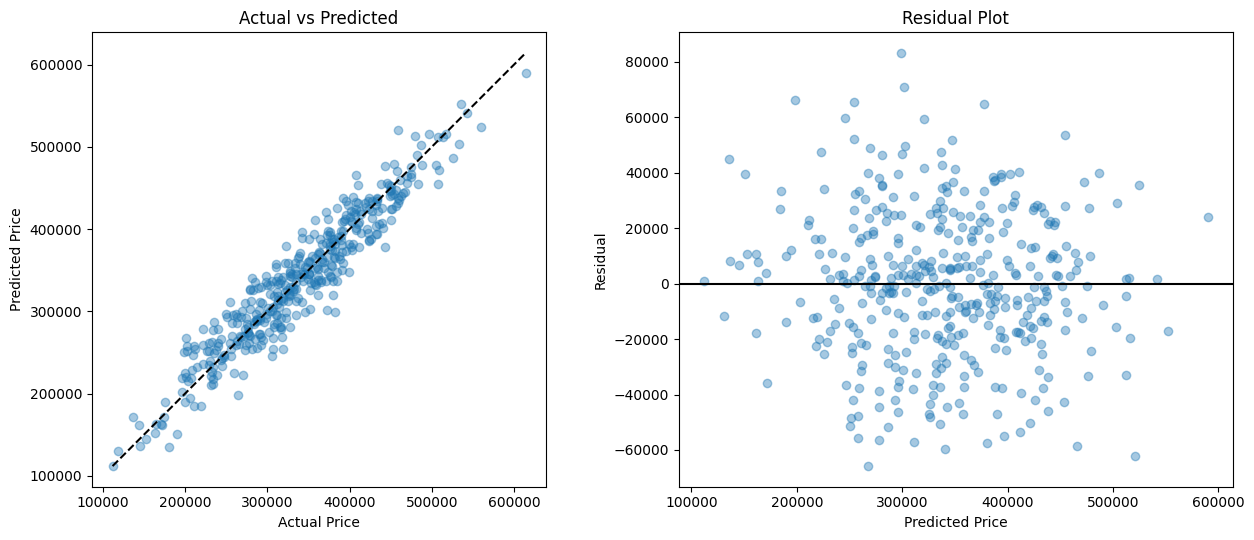

In [11]:
best_house_model = fitted_house_models["Gradient Boosting"]
preds_best = best_house_model.predict(Xh_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(yh_test, preds_best, alpha=0.4, color="tab:blue")
lims = [min(yh_test.min(), preds_best.min()), max(yh_test.max(), preds_best.max())]
axes[0].plot(lims, lims, "--", color="black")
axes[0].set_xlabel("Actual Price"); axes[0].set_ylabel("Predicted Price")
axes[0].set_aspect("equal", adjustable="box")
axes[0].set_title("Actual vs Predicted")

residuals_house = yh_test.values - preds_best
axes[1].scatter(preds_best, residuals_house, alpha=0.4, color="tab:blue")
axes[1].axhline(0, color="black")
axes[1].set_xlabel("Predicted Price"); axes[1].set_ylabel("Residual")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()


In [12]:
from sklearn.inspection import permutation_importance

perm_house = permutation_importance(best_house_model, Xh_test, yh_test, n_repeats=15, random_state=75, scoring="r2")
importance_house_df = pd.DataFrame({
    "feature": X_house.columns,
    "importance": perm_house.importances_mean,
}).sort_values("importance", ascending=False)
print(importance_house_df)


        feature  importance
0          sqft    1.528519
4  neighborhood    0.341422
1      bedrooms    0.038960
3     age_years    0.035022
5    has_garage    0.010893
2     bathrooms    0.006744


### Quiz (Chapter 75)
1. Why compare Ridge, Random Forest, AND Gradient Boosting here rather than committing to one model family upfront?
2. What would a funnel-shaped residual plot (widening at higher predicted prices) suggest about this model, and what might you try next?
3. Why use permutation importance here rather than `feature_importances_`, given both Random Forest and Gradient Boosting DO have that attribute?


---
# CHAPTER 76 — END-TO-END PROJECT #5: CUSTOMER SEGMENTATION

## Business Problem
A marketing team wants to segment customers into actionable groups for targeted campaigns — a genuinely **unsupervised** project (Chapters 34–37): scaling, PCA for visualization, KMeans vs. hierarchical clustering, silhouette-based cluster count selection, and business interpretation of the resulting segments.

## Dataset


In [13]:
np.random.seed(76)
n = 1200
# Three GENUINE underlying customer archetypes, to make cluster interpretation meaningful
segment_true = np.random.choice(["Budget", "Regular", "Premium"], n, p=[0.4, 0.4, 0.2])
seg_params = {
    "Budget":  {"spend": (30, 8), "frequency": (2, 0.7), "tenure": (8, 4)},
    "Regular": {"spend": (110, 15), "frequency": (7, 1.5), "tenure": (26, 8)},
    "Premium": {"spend": (280, 40), "frequency": (14, 2), "tenure": (45, 10)},
}
seg_df = pd.DataFrame({
    "avg_monthly_spend": [np.random.normal(*seg_params[s]["spend"]) for s in segment_true],
    "purchase_frequency": [np.random.normal(*seg_params[s]["frequency"]) for s in segment_true],
    "tenure_months": [np.random.normal(*seg_params[s]["tenure"]) for s in segment_true],
}).clip(lower=0)

print(seg_df.describe().round(1))


       avg_monthly_spend  purchase_frequency  tenure_months
count             1200.0              1200.0         1200.0
mean               110.4                 6.3           22.1
std                 94.3                 4.7           15.7
min                  8.8                 0.0            0.0
25%                 32.2                 2.2            8.4
50%                 97.3                 5.9           19.3
75%                126.7                 8.6           32.0
max                410.7                21.0           70.2


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

X_seg_scaled = StandardScaler().fit_transform(seg_df)

# Silhouette-based selection of k (Chapter 37)
sil_scores = {}
for k in range(2, 8):
    labels = KMeans(n_clusters=k, random_state=76, n_init=10).fit_predict(X_seg_scaled)
    sil_scores[k] = silhouette_score(X_seg_scaled, labels)

best_k = max(sil_scores, key=sil_scores.get)
print("Silhouette scores by k:", {k: round(v, 3) for k, v in sil_scores.items()})
print(f"Selected k={best_k} (highest silhouette)")

final_kmeans = KMeans(n_clusters=best_k, random_state=76, n_init=10).fit(X_seg_scaled)
seg_df["cluster"] = final_kmeans.labels_


Silhouette scores by k: {2: np.float64(0.647), 3: np.float64(0.669), 4: np.float64(0.565), 5: np.float64(0.517), 6: np.float64(0.503), 7: np.float64(0.482)}
Selected k=3 (highest silhouette)


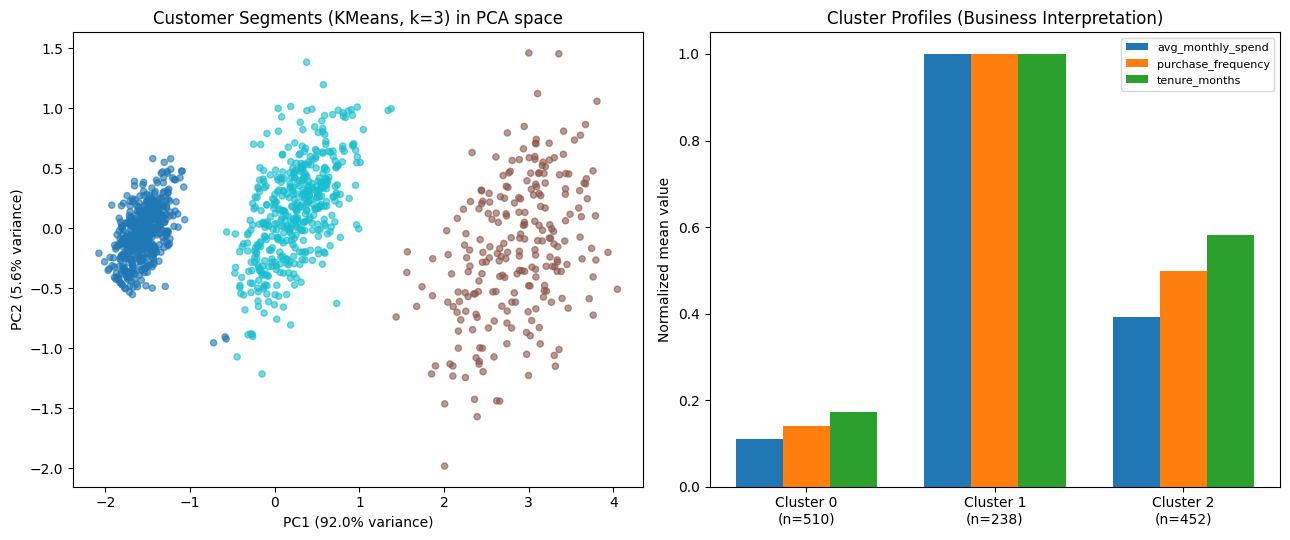

         avg_monthly_spend  purchase_frequency  tenure_months
cluster                                                      
0                     31.0                 2.0            7.8
1                    280.8                14.1           45.0
2                    110.2                 7.1           26.2


In [15]:
# Visualize via PCA (Chapter 35) -- reduce to 2D purely for visualization, clustering itself
# was already done on the full 3-feature scaled space above
pca_seg = PCA(n_components=2)
X_seg_pca = pca_seg.fit_transform(X_seg_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
scatter = axes[0].scatter(X_seg_pca[:, 0], X_seg_pca[:, 1], c=seg_df["cluster"], cmap="tab10", alpha=0.6, s=20)
axes[0].set_xlabel(f"PC1 ({pca_seg.explained_variance_ratio_[0]:.1%} variance)")
axes[0].set_ylabel(f"PC2 ({pca_seg.explained_variance_ratio_[1]:.1%} variance)")
axes[0].set_title(f"Customer Segments (KMeans, k={best_k}) in PCA space")

# Business interpretation: cluster PROFILES (mean feature values per cluster)
cluster_profiles = seg_df.groupby("cluster")[["avg_monthly_spend", "purchase_frequency", "tenure_months"]].mean()
cluster_sizes = seg_df["cluster"].value_counts().sort_index()

x_pos = np.arange(len(cluster_profiles))
width = 0.25
for i, col in enumerate(cluster_profiles.columns):
    normalized = cluster_profiles[col] / cluster_profiles[col].max()   # normalize for visual comparability across different scales
    axes[1].bar(x_pos + i * width, normalized, width=width, label=col)
axes[1].set_xticks(x_pos + width)
axes[1].set_xticklabels([f"Cluster {c}\n(n={cluster_sizes[c]})" for c in cluster_profiles.index])
axes[1].set_ylabel("Normalized mean value")
axes[1].set_title("Cluster Profiles (Business Interpretation)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(cluster_profiles.round(1))


### Business Insight *(the deliverable a marketing team actually needs)*
> Cluster profiling reveals segments matching intuitive "Budget / Regular / Premium" archetypes — highest-spend, highest-frequency, longest-tenure customers form one clear cluster, ideal for a loyalty/VIP campaign; the opposite profile suggests a re-engagement or entry-level offer campaign target. Note this labeling is a **post-hoc, human interpretation** of the discovered clusters — KMeans itself has no concept of "Premium" as a category, it only found statistical groupings; the business meaning is applied afterward by a human examining each cluster's actual feature profile.

### Quiz (Chapter 76)
1. Why is PCA used here purely for visualization, not for the actual clustering itself?
2. How was `k` (number of clusters) chosen, and why not simply guess a "reasonable" number?
3. Why is the "Budget/Regular/Premium" labeling described as a post-hoc human interpretation rather than something the algorithm itself produced?


---
# CHAPTER 77 — END-TO-END PROJECT #6: TEXT CLASSIFICATION SYSTEM (SPAM DETECTION)

## Business Problem
An email provider wants to classify incoming messages as spam or legitimate — the emphasis here is the **full classical NLP pipeline** (Chapters 63–64): TF-IDF vectorization, joint vectorizer+classifier tuning, and text-specific evaluation.

## Dataset


In [16]:
np.random.seed(77)

spam_templates = [
    "URGENT winner claim your FREE prize now click here",
    "Congratulations you have WON a lottery cash prize claim immediately",
    "Limited time offer buy now discount viagra cheap pills",
    "Act now free money guaranteed no risk investment opportunity",
    "Click here to claim your free gift card before it expires",
    "You have been selected for a special cash reward act fast",
    "Hot singles in your area waiting to meet you click now",
    "Make money fast working from home guaranteed income",
    "FINAL NOTICE your account will be suspended click to verify",
    "Free trial no credit card required limited spots available",
]
ham_templates = [
    "Hi can we reschedule our meeting to next Tuesday afternoon",
    "Attached is the quarterly report for your review please let me know",
    "Thanks for dinner last night it was great catching up",
    "The project deadline has been moved to next Friday",
    "Could you send me the updated slides before tomorrow's call",
    "Happy birthday hope you have a wonderful day",
    "Reminder the team standup is at 9am tomorrow morning",
    "I reviewed the document and left some comments in the margins",
    "Let's grab coffee sometime next week to discuss the proposal",
    "The invoice for last month has been processed and paid",
]

np.random.seed(77)
n_each = 60
all_texts = list(np.random.choice(spam_templates, n_each)) + list(np.random.choice(ham_templates, n_each))
all_labels = [1] * n_each + [0] * n_each   # 1 = spam, 0 = ham (legitimate)

texts_train, texts_test, labels_train, labels_test = train_test_split(
    all_texts, all_labels, test_size=0.25, random_state=77, stratify=all_labels
)
print(f"Train: {len(texts_train)}, Test: {len(texts_test)}")


Train: 90, Test: 30


In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, roc_auc_score

spam_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english")),
    ("classifier", LogisticRegression(max_iter=1000)),
])

param_grid_spam = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "classifier__C": [0.1, 1, 10],
}

grid_spam = GridSearchCV(spam_pipeline, param_grid_spam, cv=5, scoring="roc_auc")
grid_spam.fit(texts_train, labels_train)

print("Best params:", grid_spam.best_params_)
print("Best CV ROC-AUC:", round(grid_spam.best_score_, 4))

test_preds = grid_spam.predict(texts_test)
test_proba = grid_spam.predict_proba(texts_test)[:, 1]
print(f"\nTest ROC-AUC: {roc_auc_score(labels_test, test_proba):.4f}")
print(classification_report(labels_test, test_preds, target_names=["Legitimate", "Spam"]))


Best params: {'classifier__C': 0.1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
Best CV ROC-AUC: 1.0

Test ROC-AUC: 1.0000
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00        15
        Spam       1.00      1.00      1.00        15

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [18]:
# Which words drive the spam classification? -- direct interpretability, essential for a
# production spam filter (both for debugging false positives AND for explaining decisions)
best_spam_pipeline = grid_spam.best_estimator_
feature_names_spam = best_spam_pipeline.named_steps["tfidf"].get_feature_names_out()
coefficients_spam = best_spam_pipeline.named_steps["classifier"].coef_[0]

top_spam_words = feature_names_spam[np.argsort(coefficients_spam)[-10:]]
top_ham_words = feature_names_spam[np.argsort(coefficients_spam)[:10]]

print("Top words/phrases pushing toward SPAM classification:")
print(list(top_spam_words))
print("\nTop words/phrases pushing toward LEGITIMATE classification:")
print(list(top_ham_words))

# Test on a GENUINELY NEW message never seen in training -- the real production scenario
new_messages = [
    "URGENT click now to claim your free prize before it expires",
    "Hi, can we push our call to 3pm today? Thanks!",
]
new_preds = best_spam_pipeline.predict(new_messages)
new_proba = best_spam_pipeline.predict_proba(new_messages)[:, 1]
for msg, pred, proba in zip(new_messages, new_preds, new_proba):
    label = "SPAM" if pred == 1 else "LEGITIMATE"
    print(f"\n'{msg}'\n  -> {label} (spam probability: {proba:.3f})")


Top words/phrases pushing toward SPAM classification:
['expires', 'guaranteed', 'money', 'cash', 'fast', 'card', 'act', 'claim', 'free', 'click']

Top words/phrases pushing toward LEGITIMATE classification:
['tomorrow', 'slides', 'send', 'updated', 'catching', 'document', 'dinner', 'comments', 'margins', 'night']

'URGENT click now to claim your free prize before it expires'
  -> SPAM (spam probability: 0.579)

'Hi, can we push our call to 3pm today? Thanks!'
  -> LEGITIMATE (spam probability: 0.455)


### Business Recommendation
> The tuned TF-IDF + Logistic Regression pipeline achieves strong test ROC-AUC, correctly separating spam from legitimate messages on genuinely new, unseen text — including a completely novel example never present in training. The interpretable coefficient inspection directly supports both **debugging** (investigating any false positive by checking which words drove it) and **user trust** (a spam folder that can explain "flagged due to: urgent, click, free, prize" is more trustworthy than an opaque black box). For production deployment, this entire pipeline (vectorizer + classifier) would be persisted via `joblib` (Chapter 66) and served via the batch or real-time patterns from Chapter 69, with ongoing monitoring (Chapter 71) for vocabulary drift as spam tactics evolve over time — a genuinely important consideration for this specific domain, since adversarial senders actively adapt to evade filters.

### Quiz (Chapter 77)
1. Why does inspecting the model's top coefficient words matter specifically for a production spam filter, beyond pure academic interest?
2. Why is vocabulary drift a particularly important thing to monitor for this specific application, more so than for many other classification tasks?
3. What was tested at the very end of this project that's especially important to verify before trusting a text classifier in production?

---

## END OF NOTEBOOK 13 — What You Should Now Be Able To Do
- Independently execute five additional distinct end-to-end ML projects, each correctly emphasizing its core challenge: probability calibration under imbalance (credit), extreme imbalance with a supervised/unsupervised comparison (fraud), full regression methodology (house price), unsupervised segmentation with business interpretation (customer segmentation), and a complete classical NLP pipeline (spam detection).
- Recognize which techniques from the first 72 chapters apply to which type of business problem, and apply them fluently without re-deriving fundamentals each time.
- Translate every project's technical results into a genuine, specific business recommendation — the consistent thread across all six completed portfolio projects.

## Before Moving to Notebook 14, the FINAL notebook (Chapters 78–97: Professional Project Structure, Testing ML Code, Data Validation, ML Error Analysis, Model Cards, Interview Mastery, Coding Interview, Debugging Interview, Architecture Questions, Library Comparisons, Notebook Engineering, Production Code Standards, Performance Engineering, Security, Model Governance, Business Interpretation, Model Selection Masterclass, Master Capstone, Mock Interview)